UNIVERSIDADE DO VALE DO ITAJAÍ<br>
ESCOLA POLITÉCNICA<br>
CURSO DE ENGENHARIA DE COMPUTAÇÃO<br>
<br>
Implementação: Sydney Matheus de Souza<br>
Orientação: Felipe Viel<br>
** Não compartilhar ou deixar público esse código.<br>
<br>
Código utilizado para a implementação, teste e análise da etapa de desenvolvimento do TCC.

# Initialization

## Drive Mount

In [ ]:
#Google Drive + Colab
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


## Libs

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os as os
import sys
import scipy.io as sio
import pandas as pd
import tensorflow as tf

#Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report

#Keras
#!pip install np_utils
#from keras.utils import np_utils
from keras.optimizers import Adam

#CNN Modelling
import time
import keras
from keras.models import Sequential
from keras.layers import Input
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import Dropout
from keras.layers import Conv1D
from keras.callbacks import EarlyStopping
from keras.layers import Conv2D
from keras.utils import plot_model
from keras.utils import to_categorical

#Segmentação - SEEDS
import cv2 as cv

## GPU

In [ ]:
# Find out NVIDIA GPU model (randomly assigned by Colab)
# Deep learning performance: K80 < P4 < T4 < P100
# https://ai-benchmark.com/ranking_deeplearning.html
!python -V
gpu = !nvidia-smi -L
gpu = gpu[0].split(' (')[0]
if 'failed' in gpu:
  print('GPU: None')
else:
  print(gpu, '\n')
  # GPU information
  !nvidia-smi'

Python 3.10.12
GPU 0: Tesla T4 

/bin/bash: -c: line 1: unexpected EOF while looking for matching `''
/bin/bash: -c: line 2: syntax error: unexpected end of file


# Global

In [ ]:
#Variáveis Globais

#Diretório principal
dataRoot = 'drive/MyDrive/'
#Diretório de dados
dataDir = dataRoot+'/dataHSI/'

#Dataset a ser usado
##IP -- Indian Pines
##SA -- Salinas
##PU -- PaviaU
dataset = 'PU'

#Nome do Modelo
TF_MODEL = dataset + "_CNN"
#Quantidade de dados que devem ser colocados no treino
test_ratio = 0.15 #0.3
#Parte da base de teste que vai para validação
valid_ratio = 0.5 #0.2

#Considerando segmentação True, sem segmentação False
two_input = True

# Data Prep

## Load

In [ ]:
def loadData(input_str):
  """
    Retorna uma base de dados com suas labels

    Argumentos:
    input_str -- O nome do dataset a ser considerado podendo ser:
      IP -- Indian Pines
      SA -- Salinas
      PU -- PaviaU

    Retorno:
    (data, labels)
  """
  data_path = os.path.join(os.getcwd(),dataDir)
  if input_str == "IP":
    data = sio.loadmat(os.path.join(data_path, 'Indian_pines_corrected.mat'))['indian_pines_corrected']
    labels = sio.loadmat(os.path.join(data_path, 'Indian_pines_gt.mat'))['indian_pines_gt']
  elif input_str == "SA":
    data = sio.loadmat(os.path.join(data_path, 'Salinas_corrected.mat'))['salinas_corrected']
    labels = sio.loadmat(os.path.join(data_path, 'Salinas_gt.mat'))['salinas_gt']
  elif input_str == "PU":
      data = sio.loadmat(os.path.join(data_path, 'PaviaU.mat'))['paviaU']
      labels = sio.loadmat(os.path.join(data_path, 'PaviaU_gt.mat'))['paviaU_gt']
  else:
    raise ValueError("Entrada inválida. Por favor, insira IP, SA ou PU.")
  return data, labels

#Carregando dados em 'X' e labels em 'y'
X_load, y_load = loadData(dataset)

## Reshape for Pixel

In [ ]:
def removeBackground(X, y):
  """
  Remove todas as amostras de "fundo/background", ou seja, as amostras com classe==0.
  """
  X, y = X[y>0,:], y[y>0]
  y -= 1
  return X, y

X_re1 = X_load.copy()
y_re1 = y_load.copy()

#Dando 'reshape' para criar um array 1D com N bandas - Transformação para classificação por pixel
X_re2 = X_re1.reshape([X_re1.shape[0]*X_re1.shape[1],X_re1.shape[2]])
y_re2 = y_re1.reshape([y_re1.shape[0]*y_re1.shape[1]])

#Filtrando(tirando) algumas bandas do dataset
X_re, y_new = removeBackground(X_re2,y_re2)

print("Reshape to create a 1D array of N bands - Trasform to classify by pixels (init): ", X_re1.shape, y_re1.shape)
print("Reshape to create a 1D array of N bands - Trasform to classify by pixels (reshaped): ", X_re2.shape, y_re2.shape)
print("Reshape to create a 1D array of N bands - Trasform to classify by pixels (reshaped and filtered): ", X_re.shape, y_new.shape)

#Count samples per class
print("\nSample quantity per class in train dataset:\n", pd.DataFrame(y_new)[0].value_counts())

Reshape to create a 1D array of N bands - Trasform to classify by pixels (init):  (610, 340, 103) (610, 340)
Reshape to create a 1D array of N bands - Trasform to classify by pixels (reshaped):  (207400, 103) (207400,)
Reshape to create a 1D array of N bands - Trasform to classify by pixels (reshaped and filtered):  (42776, 103) (42776,)

Sample quantity per class in train dataset:
 1    18649
0     6631
5     5029
7     3682
3     3064
2     2099
4     1345
6     1330
8      947
Name: 0, dtype: int64


## PCA

In [ ]:
def applyPCA(X, nBands=75):
  """
  Aplica o método Principal Component Analysis
  Reduz a quantidade de bandas para nBands, levando em consideração as mais importantes.
  """
  #Número de bandas em um único pixel
  print("\nNumber of bands in a single pixel: ", X.shape[1])
  # Create a PCA object with nBands components
  model = PCA(n_components=nBands, whiten=True, random_state=42)
  # Fit the PCA model to the data
  model.fit(X)
  # Transform the data using the PCA model
  print("PCA - Old data shape:", X.shape, " - ", X.dtype)
  print(X[0])
  X_out = model.transform(X)
  print("\nPCA - Transformed data shape:", X_out.shape, " - ", X_out.dtype)
  print("Number of bands in a single pixel after PCA: ", X_out.shape[1])
  print("Example:")
  print(X_out[0])
  return X_out, model

X_norm = X_re.copy()

####PCA
#PCA reduz a quantidade de banda (Principal Component Analysis)
#Para a base Indian Pines número de bandas será 30 para a restante 15
Kb = 30 if dataset == 'IP' else 15
X_pca, pca_model = applyPCA(X_norm, nBands=Kb)
#X_pca = X_pca.reshape(-1, Kb, 1)

X_new = X_pca.copy()

print("X dtype: ", X_new.dtype)


Number of bands in a single pixel:  103
PCA - Old data shape: (42776, 103)  -  uint16
[1447 1113  973 1053 1180 1263 1285 1320 1283 1295 1337 1317 1327 1371
 1404 1430 1461 1470 1494 1519 1523 1542 1590 1608 1587 1606 1631 1637
 1658 1697 1727 1723 1743 1787 1793 1817 1841 1862 1881 1894 1907 1905
 1892 1906 1915 1915 1933 1935 1928 1913 1925 1949 1958 1954 1937 1922
 1939 1949 1945 1951 1957 1963 1973 1955 1914 1925 1956 1953 1978 1978
 1944 1922 1918 1937 1946 1941 1940 1936 1900 1904 1917 1899 1845 1827
 1871 1869 1851 1827 1821 1820 1830 1829 1807 1793 1788 1749 1696 1708
 1714 1698 1660 1643 1610]

PCA - Transformed data shape: (42776, 15)  -  float64
Number of bands in a single pixel after PCA:  15
Example:
[ 0.99023051 -0.26738183  1.12995102  0.26812343  0.39596309  1.71407575
 -1.52539569  1.6950503  -0.18793588  0.0806929  -0.91784743 -0.28281476
 -0.07927874  1.1673374   0.88800593]
X dtype:  float64



Number of bands in a single pixel:  103
PCA - Old data shape: (207400, 103)  -  uint16
[ 647  499  464  371  291  319  365  322  296  305  277  219  219  222
  201  162  157  183  204  194  198  216  249  284  294  322  338  342
  336  342  362  365  348  341  324  316  293  274  251  244  263  248
  236  254  255  240  223  203  202  191  185  200  203  181  168  174
  185  187  165  151  144  140  149  169  192  227  287  376  493  633
  763  913 1149 1442 1759 2102 2425 2689 2895 3058 3196 3252 3195 3297
 3542 3550 3537 3545 3514 3477 3468 3433 3408 3420 3416 3335 3256 3226
 3205 3210 3221 3238 3250]

PCA - Transformed data shape: (207400, 3)  -  float64
Number of bands in a single pixel after PCA:  3
Example:
[-0.92013405  1.54299476  0.99246595]


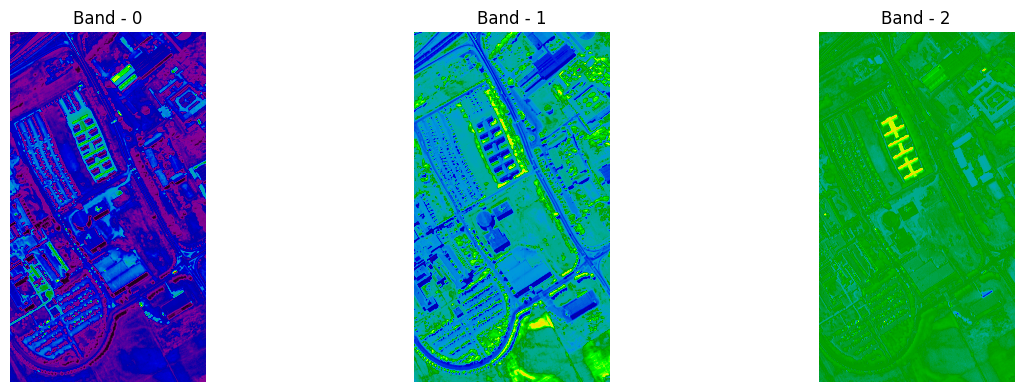

In [ ]:
if two_input:
  #Obter as três componentes principais para aplicar no algoritmo de segmentação
  X_pca_3, pca_model_3 = applyPCA(X_re2, nBands=3)

  fig = plt.figure(figsize = (20, 10))

  for i in range(0, 3):
      fig.add_subplot(2,4, i+1)
      plt.imshow(X_pca_3[:, i].reshape(X_load.shape[0], X_load.shape[1]), cmap='nipy_spectral')
      plt.axis('off')
      plt.title(f'Band - {i}')

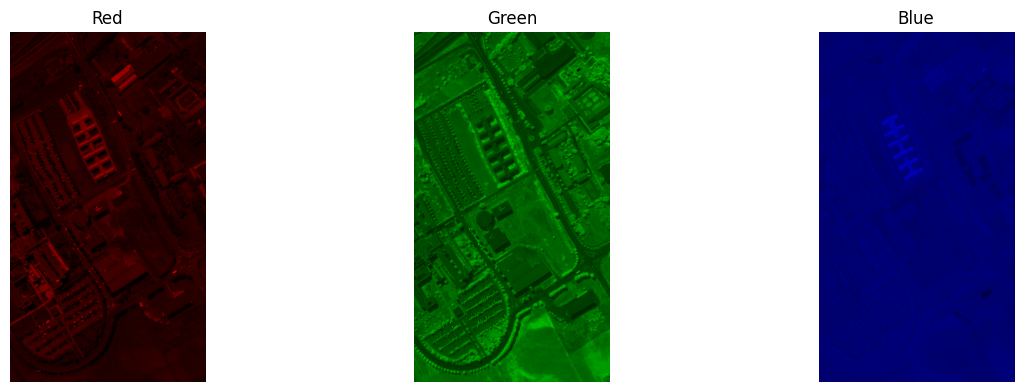

In [ ]:
def mat2gray(in_array):
  min_value = np.min(in_array)
  max_value = np.max(in_array)
  return (in_array - min_value) / (max_value - min_value)

if two_input:

  redChannel = (255 * mat2gray(X_pca_3[:, 0])).astype(np.uint8)
  greenChannel = (255 * mat2gray(X_pca_3[:, 1])).astype(np.uint8)
  blueChannel = (255 * mat2gray(X_pca_3[:, 2])).astype(np.uint8)

  fig = plt.figure(figsize = (20, 10))

  custom_colormap = plt.cm.colors.ListedColormap(np.linspace([0, 0, 0], [1, 0, 0], 256))

  fig.add_subplot(2,4, 1)
  plt.imshow(redChannel.reshape(X_load.shape[0], X_load.shape[1]), cmap=custom_colormap)
  plt.axis('off')
  plt.title('Red')

  custom_colormap = plt.cm.colors.ListedColormap(np.linspace([0, 0, 0], [0, 1, 0], 256))

  fig.add_subplot(2,4, 2)
  plt.imshow(greenChannel.reshape(X_load.shape[0], X_load.shape[1]), cmap=custom_colormap)
  plt.axis('off')
  plt.title('Green')

  custom_colormap = plt.cm.colors.ListedColormap(np.linspace([0, 0, 0], [0, 0, 1], 256))

  fig.add_subplot(2,4, 3)
  plt.imshow(blueChannel.reshape(X_load.shape[0], X_load.shape[1]), cmap=custom_colormap)
  plt.axis('off')
  plt.title('Blue')

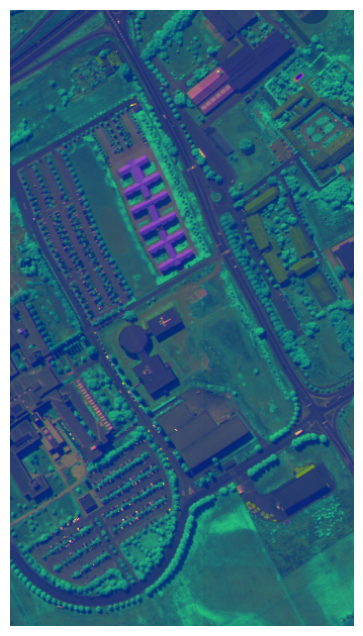

In [ ]:
if two_input:
  rgb_image = np.dstack((redChannel.reshape(X_load.shape[0], X_load.shape[1]), greenChannel.reshape(X_load.shape[0], X_load.shape[1]), blueChannel.reshape(X_load.shape[0], X_load.shape[1])))

  fig = plt.figure(figsize = (10, 8))
  plt.imshow(rgb_image)
  plt.axis('off')

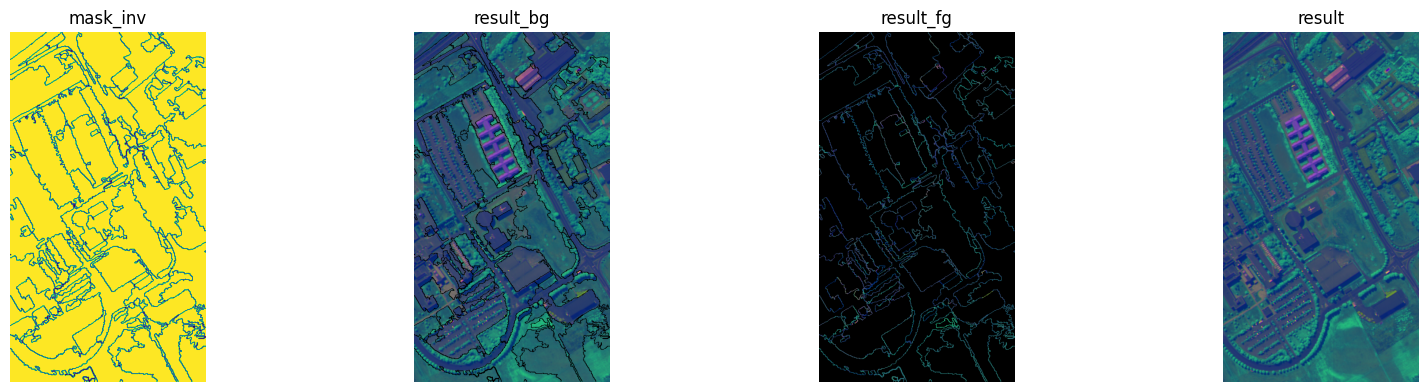

In [ ]:
if two_input:
  height,width,channels = rgb_image.shape

  if dataset == 'IP':
    num_iterations = 200#100
    prior = 2#1                              #enable 3x3 shape smoothing term if >0. A larger value leads to smoother shapes. prior must be in the range [0, 5].
    double_step = True                       #If true, iterate each block level twice for higher accuracy.
    num_superpixels = 350#400                #Desired number of superpixels. Note that the actual number may be smaller due to restrictions (depending on the image size and num_levels). Use getNumberOfSuperpixels() to get the actual number.
    num_levels = 10#10                       #Number of block levels. The more levels, the more accurate is the segmentation, but needs more memory and CPU time. (N notei diferença no resultado aumentando)
    num_histogram_bins = 5#5                 #Number of histogram bins.

  elif dataset == 'SA':
    num_iterations = 150
    prior = 1
    double_step = True
    num_superpixels = 150#300 ou 150
    num_levels = 8
    num_histogram_bins = 15

  else:
    num_iterations = 150
    prior = 1
    double_step = True
    num_superpixels = 150#300 ou 150
    num_levels = 8
    num_histogram_bins = 15

  seeds = cv.ximgproc.createSuperpixelSEEDS(width, height, channels, num_superpixels, num_levels, prior, num_histogram_bins,double_step)
  seeds.iterate(rgb_image, num_iterations)

  # retrieve the segmentation result
  labels_sp = seeds.getLabels()

  mask = seeds.getLabelContourMask(False)

  # stitch foreground & background together
  mask_inv = cv.bitwise_not(mask)
  result_bg = cv.bitwise_and(rgb_image, rgb_image, mask=mask_inv)
  result_fg = cv.bitwise_and(rgb_image, rgb_image, mask=mask)
  result = cv.add(result_bg, result_fg)

  fig = plt.figure(figsize = (20, 10))

  fig.add_subplot(2,4, 1)
  plt.imshow(mask_inv)
  plt.axis('off')
  plt.title(f'mask_inv')

  fig.add_subplot(2,4, 2)
  plt.imshow(result_bg)
  plt.axis('off')
  plt.title(f'result_bg')

  fig.add_subplot(2,4, 3)
  plt.imshow(result_fg)
  plt.axis('off')
  plt.title(f'result_fg')

  fig.add_subplot(2,4, 4)
  plt.imshow(result)
  plt.axis('off')
  plt.title(f'result')

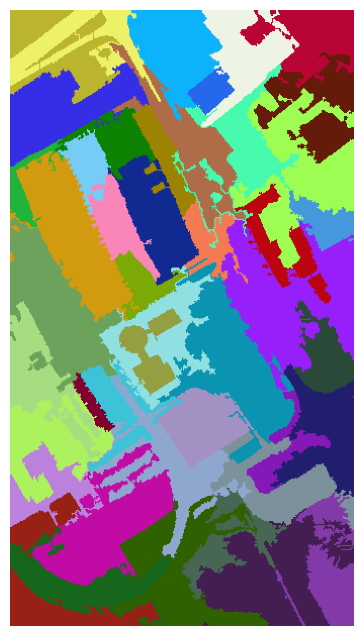

In [ ]:
if two_input:
  # create a blank image for coloring the segments
  segmented_img = np.zeros_like(rgb_image)

  # assign random colors to each segment
  for label in np.unique(labels_sp):
      color = np.random.randint(0, 256, size=3)
      segmented_img[labels_sp == label] = color

  # display the segmented image
  plt.figure(figsize=(10, 8))
  plt.imshow(cv.cvtColor(segmented_img, cv.COLOR_BGR2RGB))
  plt.axis('off')
  plt.show()

In [ ]:
if two_input:
  labels_re = labels_sp.reshape([labels_sp.shape[0]*labels_sp.shape[1],1])
  labels_re_1, _ = removeBackground(labels_re,y_re2)

  print(labels_re_1.shape)
  print(y_new.shape)

  labels_replicated = np.tile(labels_re_1, Kb)
  y_new_reshaped = y_new.reshape(-1, 1)

  print("Replicated the labels for the number total of bands: ", labels_replicated.shape)

  labels_replicated = labels_replicated.reshape(-1, Kb, 1)
  labels_replicated = np.expand_dims(labels_replicated, axis=-1)

  print("Reshape input data: ", labels_replicated.shape, " Type: ", labels_replicated.dtype)

(42776, 1)
(42776,)
Replicated the labels for the number total of bands:  (42776, 15)
Reshape input data:  (42776, 15, 1, 1)  Type:  int32


## Reshape for CNN

In [ ]:
#Será utilizado no modelo NN, basicamente o modelo necessita de um 'shape' específico
print("Reshape input data - Previous: ", X_new.shape)
X_new = X_new.reshape(-1, Kb, 1)
print("Reshape input data - After: ", X_new.shape)
X_new = np.expand_dims(X_new, axis=-1)
print("Reshape input data - After2: ", X_new.shape, " Type: ", X_new.dtype)

Reshape input data - Previous:  (42776, 15)
Reshape input data - After:  (42776, 15, 1)
Reshape input data - After2:  (42776, 15, 1, 1)  Type:  float64


In [ ]:
#Stack input of first and second input
if two_input:
  x_train_comp = np.stack((X_new, labels_replicated), axis=4)
  print("Two inputs will be considered.")
else:
  print("Only one input will be considered.")

Two inputs will be considered.


## Split Base

In [ ]:
#Separar a base de treino e de teste+validacao do Dataset
#Stratify: Proportion of samples from each class is maintained in both the training and testing
if two_input:
  X_train, X_val_and_test, y_train, y_val_and_test = train_test_split(x_train_comp, y_new, test_size=test_ratio, random_state=42,stratify=y_new)
else:
  X_train, X_val_and_test, y_train, y_val_and_test = train_test_split(X_new, y_new, test_size=test_ratio, random_state=42,stratify=y_new) #Original

In [ ]:
#(One-hot encoding) Precisamos deixar em um 'vetor de bits' devido a função de perda loss='categorical_crossentropy'
y_train = to_categorical(y_train)
y_val_and_test = to_categorical(y_val_and_test)

#Separar a base de teste e de validação do Dataset
X_test, X_val, y_test, y_val = train_test_split(X_val_and_test, y_val_and_test, test_size=valid_ratio, random_state=42, stratify=y_val_and_test)

print("Original - X_new:", X_new.shape, " |", X_new.dtype)
print("Reshape - X_train:", X_train.shape, " |", X_train.dtype)
print("Reshape - X_test:", X_test.shape, " |", X_test.dtype)
print("Reshape - X_validation:", X_val.shape, " |", X_val.dtype)
print("\nOriginal - y_new:", y_new.shape, " |", y_new.dtype)
print("Reshape - y_train:", y_train.shape, " |", y_train.dtype)
print("Reshape - y_test:", y_test.shape, " |", y_test.dtype)
print("Reshape - y_validation:", y_val.shape, " |", y_val.dtype)

#Pegando informações para a CNN
channels, size, classes = X_train.shape[1], X_train.shape[2], y_train.shape[1]
print("\nChannels:", channels, "\nSize: ", size, "\nClasses: ", classes)

# Separando o que é segmentação e o que é hsi
if two_input:
  x_train_hsi = X_train[:,:,:,:,0]
  x_val_hsi = X_val[:,:,:,:,0]

  x_train_segment = X_train[:,:,:,:,1]
  x_val_segment = X_val[:,:,:,:,1]

  X_test_hsi = X_test[:,:,:,:,0]
  X_test_segment = X_test[:,:,:,:,1]
  print("Data was split on HSI and segments.")

Original - X_new: (42776, 15, 1, 1)  | float64
Reshape - X_train: (36359, 15, 1, 1, 2)  | float64
Reshape - X_test: (3208, 15, 1, 1, 2)  | float64
Reshape - X_validation: (3209, 15, 1, 1, 2)  | float64

Original - y_new: (42776,)  | uint8
Reshape - y_train: (36359, 9)  | float32
Reshape - y_test: (3208, 9)  | float32
Reshape - y_validation: (3209, 9)  | float32

Channels: 15 
Size:  1 
Classes:  9
Data was split on HSI and segments.


# CNN

##Modelling

In [ ]:
#CNN function
def make_cnn_1D():
  model = Sequential()
  model.add(keras.layers.Input(shape=(channels,size)))
  # Tune the number of units in the first Dense layer
  # Choose an optimal value between 32-512
  model.add(Conv1D(filters=16, kernel_size=9, activation='relu')) #7  #9 # Convolutional 1D
  model.add(Conv1D(filters=32, kernel_size=3, activation='relu')) #5  #7 # Convolutional 1D
  model.add(Conv1D(filters=64, kernel_size=3, activation='relu')) #3  #5 # Convolutional 1D
  model.add(Conv1D(filters=64, kernel_size=3, activation='relu')) #3  #2 # Convolutional 1D
  model.add(Flatten())
  model.add(Dense(units=128, activation='relu')) #fully connected layers with 128 neurons and ReLU activation function
  model.add(Dropout(0.5)) #old 0.3
  model.add(Dense(units=64, activation='relu')) #fully connected layers with 64 neurons and ReLU activation function
  model.add(Dropout(0.5)) #old 0.3
  model.add(Dense(classes, activation='softmax')) #fully connected layers with 64 neurons and softmax activation function

  adam = Adam(learning_rate=0.001)

  #Compiling the CNN Model
  model.compile(loss='categorical_crossentropy', optimizer=adam, metrics=['accuracy'])
  return model

def make_cnn_1D_mod():
  input = keras.layers.Input(shape=(channels,size))
  conv1 = Conv1D(filters=16, kernel_size=9, activation='relu')(input)
  conv2 = Conv1D(filters=32, kernel_size=3, activation='relu')(conv1)
  conv3 = Conv1D(filters=64, kernel_size=3, activation='relu')(conv2)
  conv4 = Conv1D(filters=64, kernel_size=3, activation='relu')(conv3)
  flat = Flatten()(conv4)

  input2 = keras.layers.Input(shape=(1,))

  concat = tf.keras.layers.Concatenate()([flat, input2])

  dense1 = Dense(units=128, activation='relu')(concat)
  drop1 = Dropout(0.5)(dense1)
  dense2 = Dense(units=64, activation='relu')(drop1)
  drop2 = Dropout(0.5)(dense2)
  dense3 = Dense(classes, activation='softmax')(drop2)

  model = tf.keras.models.Model(inputs=[input, input2], outputs=dense3)

  adam = Adam(learning_rate=0.001)

  model.compile(loss='categorical_crossentropy', optimizer=adam, metrics=['accuracy'])
  return model

if two_input:
  model = make_cnn_1D_mod()
else:
  model = make_cnn_1D()

print(model.summary())

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_3 (InputLayer)        [(None, 15, 1)]              0         []                            
                                                                                                  
 conv1d_4 (Conv1D)           (None, 7, 16)                160       ['input_3[0][0]']             
                                                                                                  
 conv1d_5 (Conv1D)           (None, 5, 32)                1568      ['conv1d_4[0][0]']            
                                                                                                  
 conv1d_6 (Conv1D)           (None, 3, 64)                6208      ['conv1d_5[0][0]']            
                                                                                            

## Train

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5)
NUM_EPOCHS = 60 #qtt of epochs
BATCH_SIZE = 32 #batch_size
#Training/Fitting the CNN Model

if two_input:
  x_train_segment_transf = x_train_segment[:, 0, 0, 0].reshape(-1, 1)
  x_val_segment_transf = x_val_segment[:, 0, 0, 0].reshape(-1, 1)
  history = model.fit([x_train_hsi, x_train_segment_transf], y=y_train, batch_size=BATCH_SIZE, epochs=NUM_EPOCHS, validation_data=([x_val_hsi, x_val_segment_transf], y_val), callbacks=[early_stopping])
else:
  history = model.fit(x=X_train, y=y_train, batch_size=BATCH_SIZE, epochs=NUM_EPOCHS, validation_data=(X_val, y_val), callbacks=[early_stopping])

Epoch 1/60
1137/1137 [==============================] - 11s 6ms/step - loss: 0.8378 - accuracy: 0.7261 - val_loss: 0.1791 - val_accuracy: 0.9476
Epoch 2/60
1137/1137 [==============================] - 7s 6ms/step - loss: 0.2247 - accuracy: 0.9272 - val_loss: 0.0843 - val_accuracy: 0.9716
Epoch 3/60
1137/1137 [==============================] - 7s 6ms/step - loss: 0.1493 - accuracy: 0.9515 - val_loss: 0.0760 - val_accuracy: 0.9763
Epoch 4/60
1137/1137 [==============================] - 7s 6ms/step - loss: 0.1246 - accuracy: 0.9616 - val_loss: 0.0616 - val_accuracy: 0.9794
Epoch 5/60
1137/1137 [==============================] - 7s 6ms/step - loss: 0.1088 - accuracy: 0.9684 - val_loss: 0.0648 - val_accuracy: 0.9816
Epoch 6/60
1137/1137 [==============================] - 9s 8ms/step - loss: 0.0955 - accuracy: 0.9706 - val_loss: 0.0618 - val_accuracy: 0.9779
Epoch 7/60
1137/1137 [==============================] - 6s 6ms/step - loss: 0.0914 - accuracy: 0.9732 - val_loss: 0.0595 - val_accuracy

## Plotting Loss

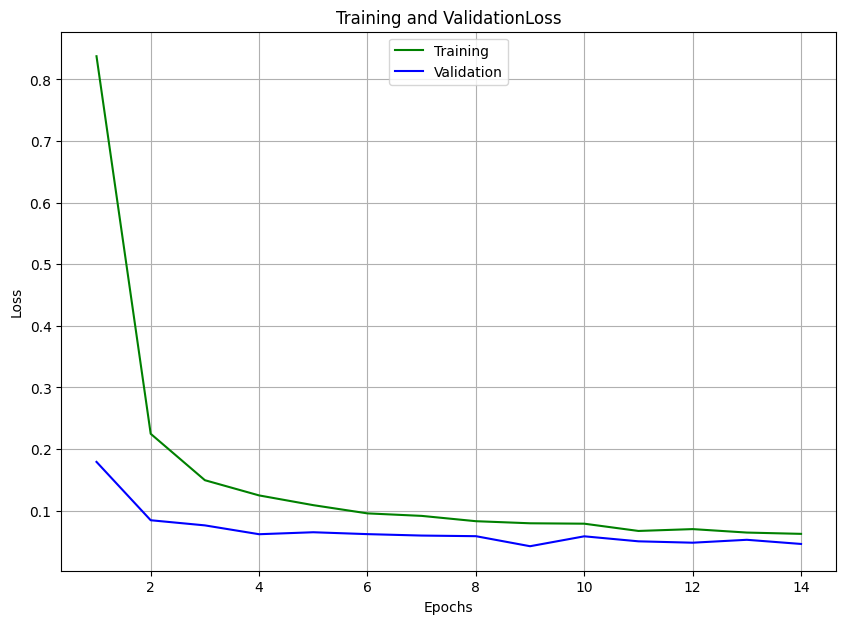

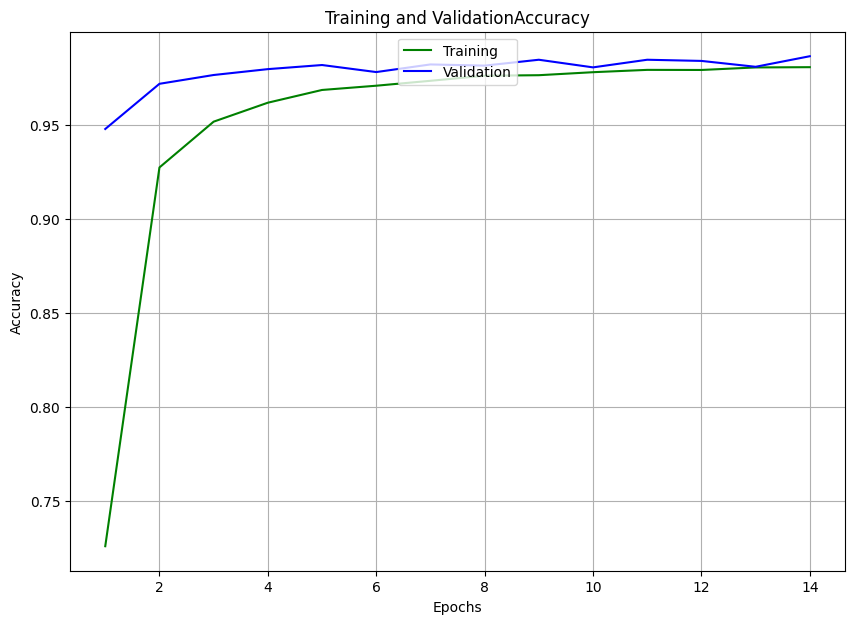

In [ ]:
#Loss function plot - Train and Validation
loss_train = history.history['loss']
loss_val   = history.history['val_loss']
acc_train  = history.history['accuracy']
acc_val    = history.history['val_accuracy']
epochs     = range(1, early_stopping.stopped_epoch + 1 + 1)

def plot_train_val_history(x, y_train, y_val, type_txt):
  plt.figure(figsize = (10,7))
  plt.plot(x, y_train, 'g', label='Training'+type_txt)
  plt.plot(x, y_val, 'b', label='Validation'+type_txt)
  plt.title('Training and Validation'+type_txt)
  plt.xlabel('Epochs')
  plt.ylabel(type_txt)
  plt.legend(['Training','Validation'], loc='upper center')
  plt.grid()
  plt.savefig(type_txt + "_curve_CNN.pdf")
  plt.show()

plot_train_val_history(epochs, loss_train, loss_val, "Loss")
plot_train_val_history(epochs, acc_train, acc_val, "Accuracy")

# Evaluating


## Predict

In [ ]:
if two_input:
  x_test_segment_reshape = X_test_segment[:, 0, 0, 0].reshape(-1, 1)
  prediction = model.predict([X_test_hsi, x_test_segment_reshape])
else:
  prediction = model.predict(X_test)

predicted_class = np.argmax(prediction, axis=1) #Pegar indice máximo de cada Row

101/101 [==============================] - 0s 3ms/step


## Results

In [ ]:
classification = classification_report(np.argmax(y_test, axis=1), predicted_class, zero_division=1)
print(classification)

#original_stdout = sys.stdout # Save a reference to the original standard output
#with open('result_CNN1D.txt', 'w') as f:
#    sys.stdout = f # Change the standard output to the file we created.
#    print(classification)
#    sys.stdout = original_stdout # Reset the standard output to its original value


###### VIEL (KAPPA):
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, cohen_kappa_score
from operator import truediv

def AA_andEachClassAccuracy(confusion_matrix):
    counter = confusion_matrix.shape[0]
    list_diag = np.diag(confusion_matrix)
    list_raw_sum = np.sum(confusion_matrix, axis=1)
    each_acc = np.nan_to_num(truediv(list_diag, list_raw_sum))
    average_acc = np.mean(each_acc)
    return each_acc, average_acc

oa = accuracy_score(np.argmax(y_test, axis=1), predicted_class)
confusion = confusion_matrix(np.argmax(y_test, axis=1), predicted_class)
each_acc, aa = AA_andEachClassAccuracy(confusion)
kappa = cohen_kappa_score(np.argmax(y_test, axis=1), predicted_class)

if two_input:
  score = model.evaluate([X_test_hsi, x_test_segment_reshape], y_test, batch_size=32)
else:
  score = model.evaluate(X_test, y_test, batch_size=32)

Test_Loss =  score[0]*100

print("OA:   ", oa)
print("AA:   ", aa)
print("kappa:", kappa)

              precision    recall  f1-score   support

           0       0.95      0.97      0.96       497
           1       0.99      1.00      1.00      1399
           2       1.00      0.97      0.99       157
           3       0.97      0.97      0.97       230
           4       1.00      1.00      1.00       101
           5       1.00      0.99      0.99       377
           6       0.96      0.92      0.94       100
           7       0.96      0.93      0.95       276
           8       1.00      1.00      1.00        71

    accuracy                           0.98      3208
   macro avg       0.98      0.97      0.98      3208
weighted avg       0.98      0.98      0.98      3208

101/101 [==============================] - 0s 3ms/step - loss: 0.0554 - accuracy: 0.9819
OA:    0.9819201995012469
AA:    0.9734646262592993
kappa: 0.9760172719363258


## Evaluating (Livro)

101/101 [==============================] - 0s 2ms/step
Accuracy:   0.9994678020223523
Recall:     1.0
Precision:  0.9992831541218637
F-score:    0.9996414485478665


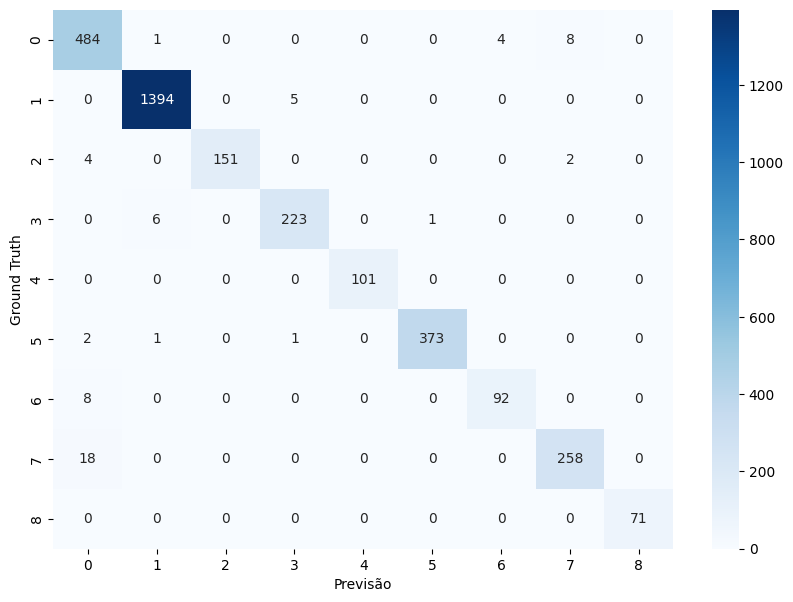

<Figure size 1000x700 with 0 Axes>

In [ ]:
import seaborn as sns
#
#Visualize the confusion matrix
#

if two_input:
  prediction_livro = model.predict([X_test_hsi, x_test_segment_reshape])
else:
  prediction_livro = model.predict(X_test) #usar treino ao invés de test

prediction_livro = (prediction_livro > 0.50).astype("int32")
predicted_class_livro = np.argmax(prediction_livro, axis=1)

cm = confusion_matrix(np.argmax(y_test, axis=1), predicted_class_livro)

#index_names  = ["Actual No Snow", "Actual Snow"]
#column_names = ["Predicted No Snow", "Predicted Snow"]

df_cm = pd.DataFrame(cm)#, index = index_names, columns = column_names)

plt.figure(figsize = (10,7))
sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues")
plt.xlabel("Previsão")
plt.ylabel("Ground Truth")
plt.figure(figsize = (10,7))

#
#Calculate Recall, Precision, and F-score performance metrics
#
TN = cm[0][0]
TP = cm[1][1]
FN = cm[1][0]
FP = cm[0][1]

accuracy = (TP + TN) / (TP + TN + FN + FP)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f_score = (2 * recall * precision) / (recall + precision)

print("Accuracy:  ",accuracy)#, round(accuracy, 3))
print("Recall:    ",recall)#, round(recall, 3))
print("Precision: ",precision)#, round(precision, 3))
print("F-score:   ",f_score)#, round(f_score, 3))

<Figure size 1000x700 with 0 Axes>

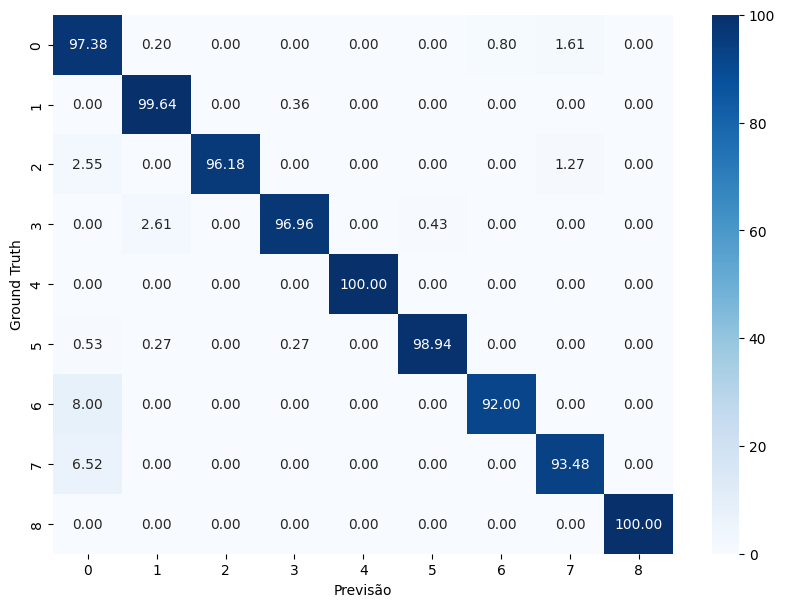

<Figure size 1000x700 with 0 Axes>

In [ ]:
cm = confusion_matrix(np.argmax(y_test, axis=1), predicted_class_livro)

# Normalize the confusion matrix
normalized_cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

df_cm = pd.DataFrame(normalized_cm*100)

plt.figure(figsize=(10, 7))
sns.heatmap(df_cm, annot=True, fmt='.2f', cmap="Blues")
plt.xlabel("Previsão")
plt.ylabel("Ground Truth")
plt.figure(figsize = (10,7))